# Mind the Stability Gap
### How much of the perovskite solar cell literature actually measures lifetime?

**Author:** James Fox · Intro to AI & Machine Learning, Fall 2026

**The question.** Perovskite solar cells went from under 4% efficiency in 2009 to over 25% about a decade later, yet they are still not on rooftops at scale. The usual explanation is *stability*. If stability is the bottleneck, how much of the published literature measures it, and is that data good enough for machine learning to learn from?

**Why I care.** I come from university technology transfer, where the first question a licensee asks about a new material is "how long does it last?" This notebook checks how often the literature can answer that question.

**What this notebook does**
1. Downloads the open [Perovskite Database](https://www.perovskitedatabase.com/) (Jacobsson et al., *Nature Energy*, 2022) automatically.
2. Measures the **reporting gap**: how many devices have any stability data, and what kind of test was run.
3. Measures the **censoring gap**: why the most stable devices are the ones missing a lifetime number.
4. Trains a **random forest** to predict lifetime (T80) and checks whether more data or better data would help.
5. Applies a **commercialization lens**: how many published tests resemble the conditions products are certified under.

It runs top to bottom in Google Colab in a minute or two, with nothing to install.

## 1. Setup

In [1]:
# Standard data-science stack; everything here comes pre-installed in Google Colab.
import os, re, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

# Chart style: quiet axes and gridlines so the data does the talking
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b3ab"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
SOURCE = "Source: The Perovskite Database (Jacobsson et al., Nature Energy 2022), CC BY 4.0"
thousands = lambda v, _: f"{v/1000:g}K" if v >= 1000 else f"{v:.0f}"

pct = lambda share: f"{share:.0%}" if share >= 0.005 else "<1%"

def save(fig, name):
    # Saves each chart as a high-resolution PNG in figures/ (ready for LinkedIn)
    fig.savefig(f"figures/{name}.png")
    plt.show()

def hbars(ax, labels, values, fmt, color=BLUE, pad=0.01, span=None):
    # Horizontal bars, top-to-bottom in the order given, with the value printed at each bar's tip
    y = np.arange(len(values))[::-1]
    ax.barh(y, values, height=0.55, color=color)
    span = span or (max(values) if max(values) > 0 else 1)
    for yi, v in zip(y, values):
        ax.text(v + span * pad, yi, fmt(v), va="center", fontsize=10, color=INK_2)
    ax.set_yticks(y, labels)
    ax.set_xlim(0, span * 1.3)
    ax.grid(axis="y", visible=False)

## 2. Get the data

The Perovskite Database Project was built by roughly 90 researchers who read the perovskite solar cell literature by hand and logged up to ~100 parameters per device: materials, layer stack, efficiency, and stability tests. This notebook uses the archived **CSV snapshot (v1.0.1, January 2022)** on Zenodo, which is licensed **CC BY 4.0**. The papers in it were mostly published between 2013 and 2019, with partial coverage of 2020. The same records can also be browsed in NOMAD.

> Jacobsson, T.J. *et al.* An open-access database and analysis tool for perovskite solar cells based on the FAIR data principles. *Nature Energy* **7**, 107–115 (2022). [doi:10.1038/s41560-021-00941-3](https://doi.org/10.1038/s41560-021-00941-3) · Data: [doi:10.5281/zenodo.5834698](https://doi.org/10.5281/zenodo.5834698)

In [2]:
DATA_URL = ("https://zenodo.org/records/5837035/files/"
            "Jesperkemist/perovskitedatabase_data-v1.0.1.zip?download=1")
ZIP_PATH = "perovskitedatabase_data-v1.0.1.zip"
CSV_NAME = "Perovskite_database_content_all_data.csv"

if not os.path.exists(ZIP_PATH):
    print("Downloading the Perovskite Database snapshot from Zenodo (about 3 MB)...")
    try:
        urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    except Exception as err:
        raise RuntimeError(
            f"Download failed ({err}). Open this link in your browser:\n{DATA_URL}\n"
            "then drag the zip into Colab's Files panel (folder icon, left side) and re-run this cell.")

with zipfile.ZipFile(ZIP_PATH) as zf:
    member = next(name for name in zf.namelist() if name.endswith(CSV_NAME))
    raw = pd.read_csv(zf.open(member), low_memory=False)

print(f"Loaded {len(raw):,} devices x {raw.shape[1]} columns")
raw[["Ref_DOI_number", "Ref_publication_date", "Cell_architecture",
     "Perovskite_composition_short_form", "JV_default_PCE", "Stability_measured"]].head()

Loaded 42,443 devices x 410 columns


,Ref_DOI_number,Ref_publication_date,Cell_architecture,Perovskite_composition_short_form,JV_default_PCE,Stability_measured
0,10.1021/jp5126624,2015-01-06,nip,CsSnI,0.00,False
1,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.00,False
2,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.13,False
3,10.1021/jp5126624,2015-01-06,nip,CsSnBrI,0.12,False
4,10.1021/jp5126624,2015-01-06,nip,CsSnBr,0.10,False


## 3. Clean it up

The database marks missing information in several ways: blank cells, `Unknown`, `nan`, and range placeholders like `nan; nan`. Yes/no fields are stored as `TRUE`/`FALSE` text, and ranges are written as `min; max`. The helpers below turn all of that into a tidy table, one row per device.

Field definitions come from the database's own documentation (*description of data content v5.4*). Two definitions matter most here:
- **T80**: hours until a device's efficiency drops to 80% of its starting value.
- **Efficiency at end of experiment**: percent of the starting efficiency the device kept when the test stopped.

The database also tags each stability test with an **ISOS category**, the standard test types defined in the 2020 consensus statement (Khenkin *et al.*, *Nature Energy* 2020). Papers from as early as 2013 carry these tags, so the database curators must have assigned them by classifying each test. They describe *what kind* of test was run, not whether the authors followed a protocol. A trailing "I" means the test ran in an inert gas instead of air.

In [3]:
MISSING = {"", "nan", "none", "unknown", "n/a", "na", "-"}

def get(name):
    # Returns a column, or an all-empty column if this snapshot doesn't have it
    return raw[name] if name in raw.columns else pd.Series(np.nan, index=raw.index)

def reported(series):
    # True where a cell holds real information rather than one of the 'missing' markers
    def check(v):
        if pd.isna(v):
            return False
        return any(tok.strip().lower() not in MISSING for tok in re.split(r"[;|>]+", str(v)))
    return series.map(check).astype(bool)

def to_bool(series):
    return series.astype(str).str.strip().str.lower().isin(["true", "1", "yes"])

def to_num(series):
    # Numbers stay numbers; text like '1.6 | nan' falls back to its first number
    direct = pd.to_numeric(series, errors="coerce")
    first = pd.to_numeric(series.astype(str).str.extract(r"(-?\d+(?:\.\d+)?)")[0], errors="coerce")
    return direct.fillna(first)

def range_max(series):
    # Largest number in a 'min; max' range ('25; 85' -> 85)
    def f(v):
        nums = re.findall(r"-?\d+(?:\.\d+)?", str(v))
        return max(map(float, nums)) if nums else np.nan
    return series.map(f)

def text(series):
    return series.where(reported(series), "").astype(str).str.strip().str.lower()

def atmosphere_group(v):
    tokens = {t.strip() for t in re.split(r"[;|]", v) if t.strip()}
    if not tokens:
        return "Not reported"
    if tokens <= {"n2", "ar", "argon", "vacuum", "he", "inert"}:
        return "Inert (N2/Ar/vacuum)"
    if "dry air" in tokens:
        return "Dry air"
    if tokens & {"air", "ambient"}:
        return "Air / ambient"
    return "Other"

def bias_group(v):
    if not v:
        return "Not reported"
    for key, label in [("mpp", "MPP tracking"), ("open", "Open circuit"),
                       ("short", "Short circuit"), ("constant", "Constant bias")]:
        if key in v:
            return label
    return "Other"

TEST_TYPES = {  # ISOS category -> plain-English test type (conditions from Khenkin et al. 2020, Table 1)
    "d1": "Dark, room temperature (shelf life)",
    "d2": "Dark, heated to 65-85 °C",
    "d3": "Dark, 65-85 °C and 85% humidity (damp heat)",
    "l1": "Under light, room temperature",
    "l2": "Under light, heated to 65-85 °C",
    "l3": "Under light, heated, ~50% humidity",
    "o":  "Outdoors",
}
def test_type(v):
    v = v.replace("‐", "-").replace("‑", "-").replace(" ", "")   # some entries use unicode hyphens
    if not v:
        return "Not classified"
    m = re.match(r"isos-(lc|[dlotv])-?(\d)", v)
    if not m:
        return "Cycling, bias, IEC or other"
    kind = m.group(1) if m.group(1) == "o" else m.group(1) + m.group(2)
    return TEST_TYPES.get(kind, "Cycling, bias, IEC or other")

In [4]:
df = pd.DataFrame(index=raw.index)

# Who published it, and when
doi = text(get("Ref_DOI_number"))
df["paper"] = np.where(doi != "", doi, "no-doi-" + get("Ref_ID").astype(str))
df["year"] = pd.to_numeric(get("Ref_publication_date").astype(str)
                           .str.extract(r"((?:19|20)\d{2})")[0], errors="coerce")

# The device
df["architecture"] = text(get("Cell_architecture")).replace("", "not reported")
top_comps = text(get("Perovskite_composition_short_form")).value_counts().head(12).index
df["composition"] = text(get("Perovskite_composition_short_form")).where(lambda s: s.isin(top_comps), "other")
df["band_gap"] = to_num(get("Perovskite_band_gap")).where(lambda s: s.between(0.5, 4))
df["area_cm2"] = to_num(get("Cell_area_measured")).where(lambda s: s > 0)
df["pce"] = to_num(get("JV_default_PCE")).where(lambda s: s > 0)
df["encapsulated"] = to_bool(get("Encapsulation"))
df["module"] = to_bool(get("Module"))
df["outdoor"] = to_bool(get("Outdoor_tested"))

# The stability test
df["stability_tested"] = to_bool(get("Stability_measured"))
df["t80"] = to_num(get("Stability_PCE_T80")).where(lambda s: s > 0)
df["end_pct"] = to_num(get("Stability_PCE_end_of_experiment")).where(lambda s: s >= 0)
df["pce_initial"] = to_num(get("Stability_PCE_initial_value")).where(lambda s: s > 0).fillna(df["pce"])
df["duration_h"] = to_num(get("Stability_time_total_exposure")).where(lambda s: s > 0)
df["light_mw"] = to_num(get("Stability_light_intensity")).where(lambda s: s >= 0)
df["temp_max_c"] = range_max(get("Stability_temperature_range"))
df["rh_pct"] = to_num(get("Stability_relative_humidity_average_value")).fillna(
    range_max(get("Stability_relative_humidity_range")))
df["atmosphere"] = text(get("Stability_atmosphere")).map(atmosphere_group)
df["bias"] = text(get("Stability_potential_bias_load_condition")).map(bias_group)
dark = text(get("Stability_light_source_type")).str.contains("dark") | (df["light_mw"] == 0)
df["light_condition"] = np.select([dark, df["light_mw"] > 0], ["Dark", "Illuminated"], "Not reported")
df["test_type"] = text(get("Stability_protocol")).map(test_type)

tested = df[df["stability_tested"]]
print(f"{len(df):,} devices from {df['paper'].nunique():,} papers")
print(f"{len(tested):,} devices ({len(tested)/len(df):.1%}) have some kind of stability test")

42,443 devices from 7,358 papers
7,419 devices (17.5%) have some kind of stability test


## 4. The reporting gap

Start with the whole database and narrow it down to devices whose lifetime can be compared fairly. A fair comparison needs a lifetime number (T80) plus the test conditions behind it, because a cell kept in the dark under nitrogen and a cell running at 85 °C in humid air are not the same experiment.

Here, "core conditions" means the light, temperature, and atmosphere were all reported, plus humidity whenever the test ran in air. Humidity doesn't matter under nitrogen, so it isn't required there.

In [5]:
inert = df["atmosphere"].eq("Inert (N2/Ar/vacuum)")
core_conditions = (df["light_condition"].ne("Not reported") & df["temp_max_c"].notna()
                   & df["atmosphere"].ne("Not reported") & (inert | df["rh_pct"].notna()))

stages = [
    ("All devices in the database", pd.Series(True, index=df.index)),
    ("Efficiency reported", df["pce"].notna()),
    ("Any stability test", df["stability_tested"]),
    ("Lifetime (T80) reported", df["stability_tested"] & df["t80"].notna()),
    ("T80 + core test conditions", df["stability_tested"] & df["t80"].notna() & core_conditions),
]
funnel = pd.DataFrame({"stage": [s for s, _ in stages], "devices": [int(m.sum()) for _, m in stages]})
funnel["share_of_all"] = funnel["devices"] / len(df)
funnel["papers"] = [df.loc[m, "paper"].nunique() for _, m in stages]
funnel.style.format({"devices": "{:,}", "papers": "{:,}", "share_of_all": "{:.1%}"})

,stage,devices,share_of_all,papers
0,All devices in the database,"42,443",100.0%,"7,358"
1,Efficiency reported,"41,447",97.7%,"7,337"
2,Any stability test,"7,419",17.5%,"2,818"
3,Lifetime (T80) reported,"1,832",4.3%,963
4,T80 + core test conditions,"1,306",3.1%,693


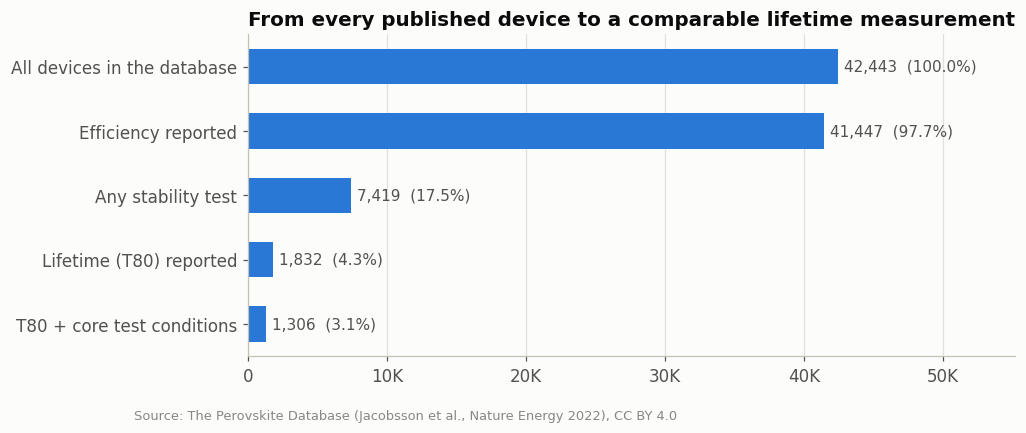

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
hbars(ax, funnel["stage"], funnel["devices"].values,
      lambda n: f"{n:,}  ({n/len(df):.1%})")
ax.xaxis.set_major_formatter(thousands)
ax.set_title("From every published device to a comparable lifetime measurement")
fig.text(0.01, -0.04, SOURCE, fontsize=8.5, color=MUTED)
save(fig, "1_reporting_funnel")

### Has stability reporting improved over time?

Only complete years with a meaningful number of devices are shown (2013–2019).

,year,devices,stability_share,t80_share
0,2013,232,3.4%,0.9%
1,2014,"1,551",6.4%,0.8%
2,2015,"3,558",7.5%,1.8%
3,2016,"6,246",11.9%,2.8%
4,2017,"8,060",15.9%,4.3%
5,2018,"10,672",19.4%,5.2%
6,2019,"10,585",23.4%,5.6%


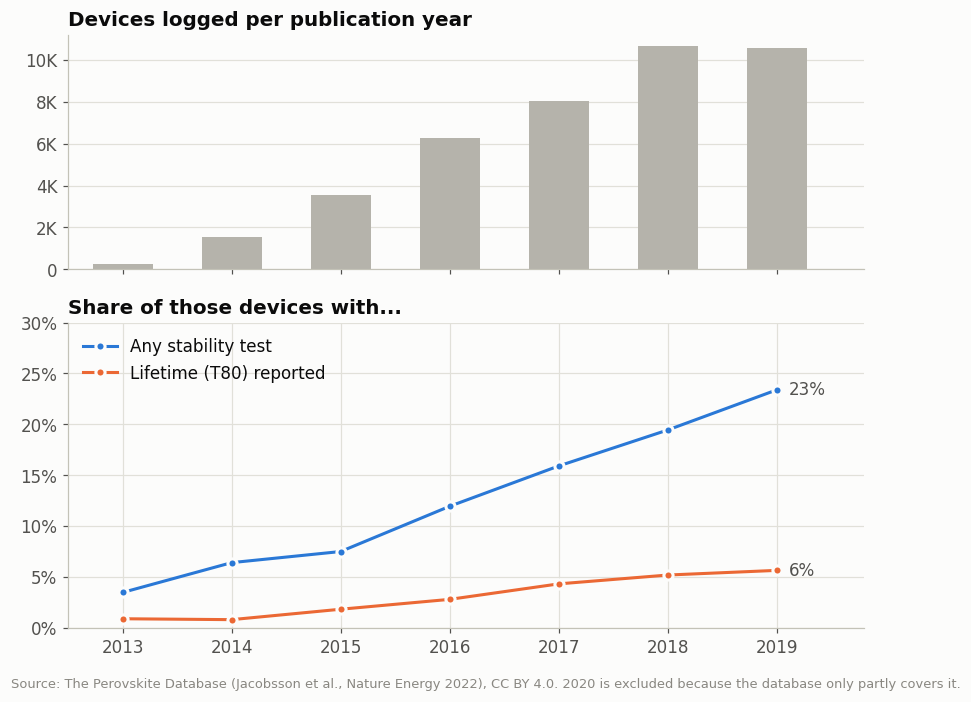

In [7]:
by_year = (df[df["year"].between(2013, 2019)].groupby("year")
           .agg(devices=("pce", "size"), stability_share=("stability_tested", "mean"),
                t80_share=("t80", lambda s: s.notna().mean()))
           .reset_index())
by_year["year"] = by_year["year"].astype(int)
display(by_year.style.format({"devices": "{:,}", "stability_share": "{:.1%}", "t80_share": "{:.1%}"}))

fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 6.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.3]})
top.bar(by_year["year"], by_year["devices"], width=0.55, color=GRAY)
top.set_title("Devices logged per publication year")
top.yaxis.set_major_formatter(thousands)
top.grid(axis="x", visible=False)

for col, color, label in [("stability_share", BLUE, "Any stability test"),
                          ("t80_share", ORANGE, "Lifetime (T80) reported")]:
    bottom.plot(by_year["year"], by_year[col] * 100, color=color, lw=2, marker="o", ms=6,
                markeredgecolor=SURFACE, markeredgewidth=2, label=label)
    bottom.annotate(f"{by_year[col].iloc[-1]:.0%}", (by_year['year'].iloc[-1], by_year[col].iloc[-1] * 100),
                    xytext=(8, 0), textcoords="offset points", va="center", color=INK_2)
bottom.set_title("Share of those devices with...")
bottom.set_ylim(0, max(30, by_year["stability_share"].max() * 125))
bottom.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
bottom.set_xticks(by_year["year"])
bottom.set_xlim(by_year["year"].min() - 0.5, by_year["year"].max() + 0.8)
bottom.legend(frameon=False, loc="upper left")
fig.text(0.01, -0.02, SOURCE + ". 2020 is excluded because the database only partly covers it.",
         fontsize=8.5, color=MUTED)
fig.tight_layout()
save(fig, "2_stability_share_by_year")

### When stability *is* tested, what kind of test is it?

Completeness first: among stability-tested devices, this is the share whose entry includes each piece of information. The curators pulled much of it from figures and methods sections, so it's fairly complete. The weak spots are humidity and the lifetime number itself.

In [8]:
fields = {
    "Test duration": tested["duration_h"].notna(),
    "Efficiency at end of test": tested["end_pct"].notna(),
    "Light (dark or intensity)": tested["light_condition"].ne("Not reported"),
    "Temperature": tested["temp_max_c"].notna(),
    "Atmosphere": tested["atmosphere"].ne("Not reported"),
    "Humidity": tested["rh_pct"].notna(),
    "Lifetime (T80)": tested["t80"].notna(),
}
pd.DataFrame({"share reported": {k: v.mean() for k, v in fields.items()}}).style.format("{:.0%}")

,share reported
Test duration,100%
Efficiency at end of test,99%
Light (dark or intensity),98%
Temperature,94%
Atmosphere,91%
Humidity,73%
Lifetime (T80),25%


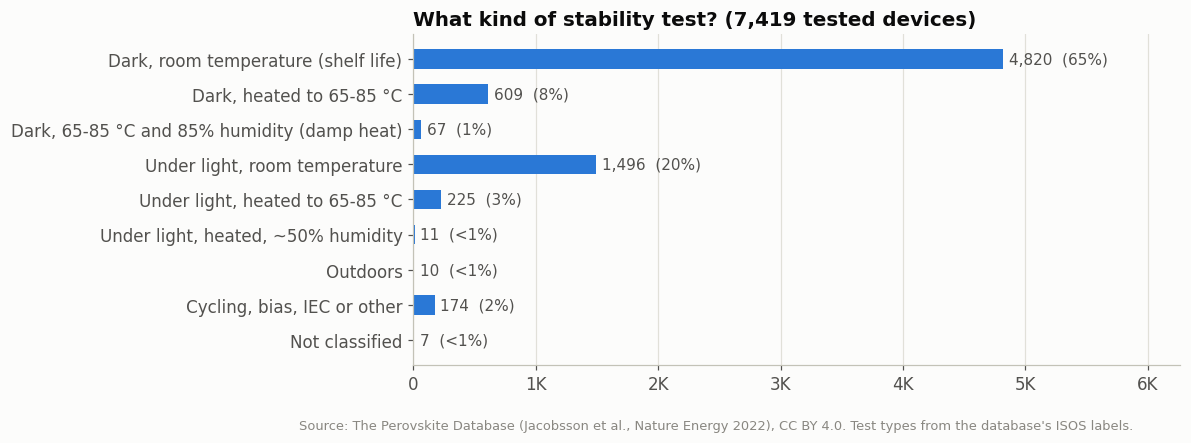

In [9]:
type_order = list(TEST_TYPES.values()) + ["Cycling, bias, IEC or other", "Not classified"]
type_counts = tested["test_type"].value_counts().reindex(type_order).fillna(0).astype(int)
type_counts = type_counts[type_counts > 0]

fig, ax = plt.subplots(figsize=(9, 3.9))
hbars(ax, type_counts.index, type_counts.values, lambda n: f"{n:,}  ({pct(n/len(tested))})")
ax.xaxis.set_major_formatter(thousands)
ax.set_title(f"What kind of stability test? ({len(tested):,} tested devices)")
fig.text(0.01, -0.04, SOURCE + ". Test types from the database's ISOS labels.", fontsize=8.5, color=MUTED)
save(fig, "3_test_types")

## 5. The censoring gap

T80 can only be measured if a device actually loses 20% of its efficiency **before the test ends**. A device that is still above 80% when the experiment stops never gets a T80, so the **most stable devices are the ones missing from the lifetime column**. Statisticians call this *right-censoring*, the same problem medical trials face when patients are still healthy when the study ends.

There's a second, plainer gap: some devices clearly dropped below 80% during the test, but no T80 was recorded for them. That can happen, for example, when a paper reports only a starting and an ending value.

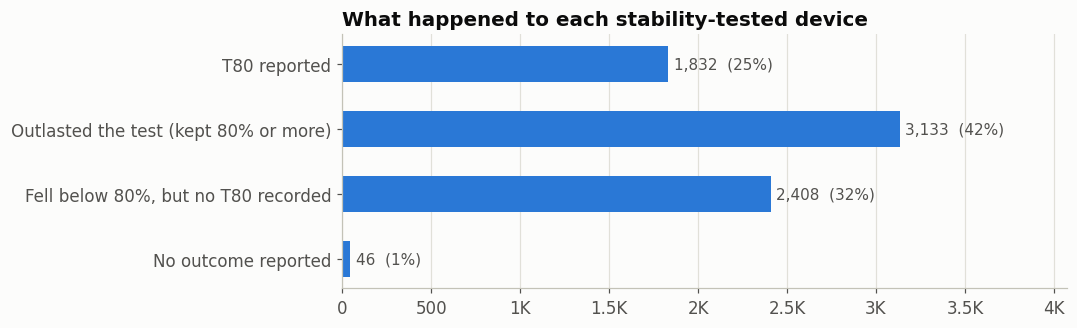

Median test length, devices WITH a T80:         400 h
Median test length, devices that outlasted it:  600 h


In [10]:
outcome = np.select(
    [tested["t80"].notna(), tested["end_pct"].ge(80), tested["end_pct"].lt(80)],
    ["T80 reported", "Outlasted the test (kept 80% or more)", "Fell below 80%, but no T80 recorded"],
    "No outcome reported")
order = ["T80 reported", "Outlasted the test (kept 80% or more)",
         "Fell below 80%, but no T80 recorded", "No outcome reported"]
outcome_counts = pd.Series(outcome).value_counts().reindex(order).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(8.5, 3.0))
hbars(ax, outcome_counts.index, outcome_counts.values, lambda n: f"{n:,}  ({pct(n/len(tested))})")
ax.xaxis.set_major_formatter(thousands)
ax.set_title("What happened to each stability-tested device")
save(fig, "4_censoring")

survivors = tested[tested["t80"].isna() & tested["end_pct"].ge(80)]
print(f"Median test length, devices WITH a T80:         {tested.loc[tested['t80'].notna(), 'duration_h'].median():,.0f} h")
print(f"Median test length, devices that outlasted it:  {survivors['duration_h'].median():,.0f} h")

## 6. Can machine learning predict lifetime from what gets reported?

**Target:** log10(T80 in hours). Lifetimes range from minutes to thousands of hours, so a log scale keeps one extreme device from dominating.

**Features:** device descriptors (architecture, perovskite composition, band gap, starting efficiency, area, encapsulation) and test conditions (light, temperature, humidity, atmosphere, electrical load), plus publication year.

**Deliberately left out:** test duration and end-of-test efficiency. Both are partly *outcomes*, since a T80 can never be longer than the test that measured it, so including them would let the model cheat.

**Two ways to grade the model:**
- *Random split:* devices from the same paper can land in both the training and the test set.
- *Grouped by paper:* every device from a paper stays on one side. Devices from one lab share equipment, recipes, and habits, so this is the honest test of whether the model learned chemistry or just memorized labs.

In [11]:
CAT = ["architecture", "composition", "atmosphere", "light_condition", "bias", "encapsulated"]
NUM = ["temp_max_c", "rh_pct", "light_mw", "pce_initial", "band_gap", "area_cm2", "year"]

data = df[df["stability_tested"] & df["t80"].notna()].copy()
data["encapsulated"] = data["encapsulated"].map({True: "yes", False: "no/unknown"})
NUM = [c for c in NUM if data[c].notna().mean() >= 0.05]   # drop features that are almost always empty
X, y, groups = data[CAT + NUM], np.log10(data["t80"]), data["paper"]
print(f"Modelling {len(data):,} devices with a T80, from {groups.nunique():,} papers")

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), CAT),
    ("num", SimpleImputer(strategy="median", add_indicator=True), NUM),
])
forest = Pipeline([("prep", preprocess),
                   ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                                   n_jobs=-1, random_state=RANDOM_STATE))])
baseline = Pipeline([("prep", preprocess), ("model", DummyRegressor(strategy="median"))])

def evaluate(model, cv, use_groups):
    r = cross_validate(model, X, y, cv=cv, groups=groups if use_groups else None,
                       scoring=("r2", "neg_mean_absolute_error"))
    mae = -r["test_neg_mean_absolute_error"].mean()
    return {"R2": r["test_r2"].mean(), "R2 spread": r["test_r2"].std(),
            "MAE (log10 h)": mae, "typical error factor": 10 ** mae}

n_splits = min(5, groups.nunique())
results = pd.DataFrame({
    "Baseline: always guess the median": evaluate(baseline, GroupKFold(n_splits), True),
    "Random forest, random split": evaluate(forest, KFold(n_splits, shuffle=True, random_state=RANDOM_STATE), False),
    "Random forest, grouped by paper": evaluate(forest, GroupKFold(n_splits), True),
}).T
results.style.format({"R2": "{:.2f}", "R2 spread": "{:.2f}", "MAE (log10 h)": "{:.2f}",
                      "typical error factor": "x{:.1f}"})

Modelling 1,832 devices with a T80, from 963 papers


,R2,R2 spread,MAE (log10 h),typical error factor
Baseline: always guess the median,-0.05,0.03,0.70,x5.0
"Random forest, random split",0.34,0.03,0.56,x3.6
"Random forest, grouped by paper",0.12,0.10,0.64,x4.4


**How to read this:** R² = 1 is a perfect model, and 0 is no better than always guessing the median. The *typical error factor* is the more intuitive number: ×3 means a typical prediction is off by a factor of three, for example predicting 300 h for a device that lasted 900 h. If the random-split score is much better than the grouped score, the model was partly memorizing labs.

### Would more data help? (learning curve)

If the score is still climbing at the right edge, more data of the same kind would help. If it has flattened, the problem is data *quality*: missing conditions, non-standard tests, and censoring.

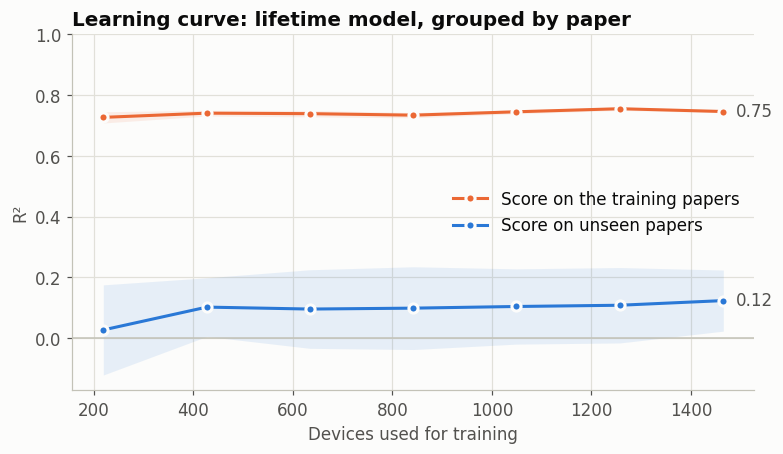

In [12]:
sizes, train_scores, val_scores = learning_curve(
    forest, X, y, groups=groups, cv=GroupKFold(n_splits), scoring="r2",
    train_sizes=np.linspace(0.15, 1.0, 7), n_jobs=-1)

fig, ax = plt.subplots(figsize=(8, 4.2))
for scores, color, label in [(train_scores, ORANGE, "Score on the training papers"),
                             (val_scores, BLUE, "Score on unseen papers")]:
    m, s = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(sizes, m, color=color, lw=2, marker="o", ms=6, markeredgecolor=SURFACE,
            markeredgewidth=2, label=label)
    ax.fill_between(sizes, m - s, m + s, color=color, alpha=0.10, lw=0)
    ax.annotate(f"{m[-1]:.2f}", (sizes[-1], m[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK_2)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_ylim(min(-0.05, (val_scores.mean(axis=1) - val_scores.std(axis=1)).min() - 0.05), 1)
ax.set_xlabel("Devices used for training")
ax.set_ylabel("R²")
ax.set_title("Learning curve: lifetime model, grouped by paper")
ax.legend(frameon=False, loc="center right")
save(fig, "5_learning_curve")

### What does the model rely on? (permutation importance)

To measure importance, hold out a quarter of the papers, shuffle one feature at a time, and see how much the score drops. A big drop means the model leaned on that feature. Orange marks how the test was run, blue marks the device itself, and gray marks publication year.

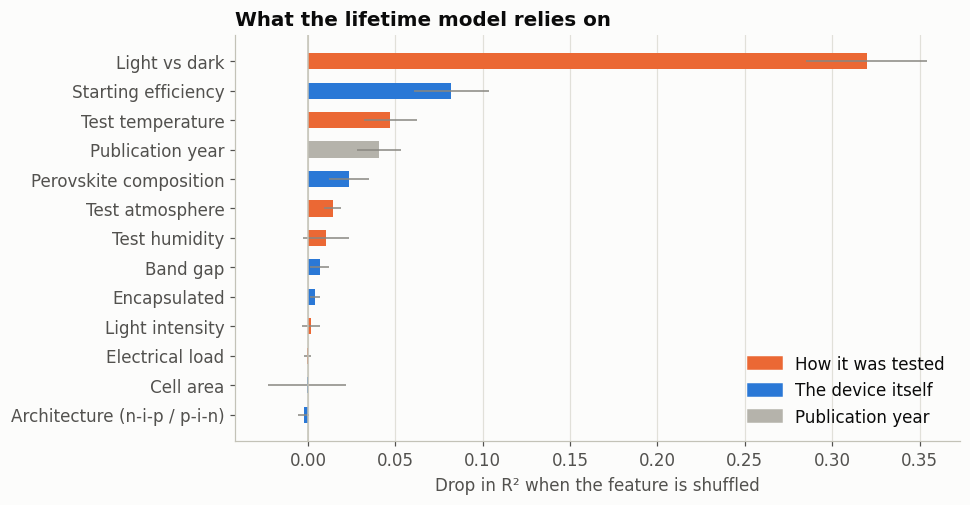

Share of total importance:
kind
How it was tested    72%
Publication year      7%
The device itself    21%


In [13]:
TEST_CONDITIONS = {"atmosphere", "light_condition", "light_mw", "temp_max_c", "rh_pct", "bias"}
LABELS = {"architecture": "Architecture (n-i-p / p-i-n)", "composition": "Perovskite composition",
          "atmosphere": "Test atmosphere", "light_condition": "Light vs dark", "bias": "Electrical load",
          "encapsulated": "Encapsulated", "temp_max_c": "Test temperature", "rh_pct": "Test humidity",
          "light_mw": "Light intensity", "pce_initial": "Starting efficiency", "band_gap": "Band gap",
          "area_cm2": "Cell area", "year": "Publication year"}

train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
                           .split(X, y, groups))
forest.fit(X.iloc[train_idx], y.iloc[train_idx])
pi = permutation_importance(forest, X.iloc[test_idx], y.iloc[test_idx], scoring="r2",
                            n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"feature": X.columns, "drop_in_R2": pi.importances_mean, "std": pi.importances_std})
imp = imp.sort_values("drop_in_R2")
imp["kind"] = np.select([imp["feature"].isin(TEST_CONDITIONS), imp["feature"].eq("year")],
                        ["How it was tested", "Publication year"], "The device itself")
KIND_COLOR = {"How it was tested": ORANGE, "The device itself": BLUE, "Publication year": GRAY}

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh([LABELS.get(f, f) for f in imp["feature"]], imp["drop_in_R2"], height=0.55,
        color=imp["kind"].map(KIND_COLOR), xerr=imp["std"], error_kw={"ecolor": MUTED, "lw": 1, "capsize": 0})
ax.axvline(0, color="#c3c2b7", lw=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Drop in R² when the feature is shuffled")
ax.set_title("What the lifetime model relies on")
ax.legend(handles=[Patch(color=c, label=k) for k, c in KIND_COLOR.items()], frameon=False, loc="lower right")
save(fig, "6_feature_importance")

by_kind = imp.groupby("kind")["drop_in_R2"].sum().clip(lower=0)
print("Share of total importance:\n" + (by_kind / by_kind.sum()).map("{:.0%}".format).to_string())

## 7. The commercialization lens

Before a solar module can be sold, it typically passes **IEC 61215**. One of its toughest tests is *damp heat*: **1,000 hours at 85 °C and 85% relative humidity**. Research-grade tests don't need to copy this exactly, since the ISOS protocols exist precisely to define lab-scale tests. Still, it's a useful yardstick for how much of the literature speaks to what a licensee or investor needs to know.

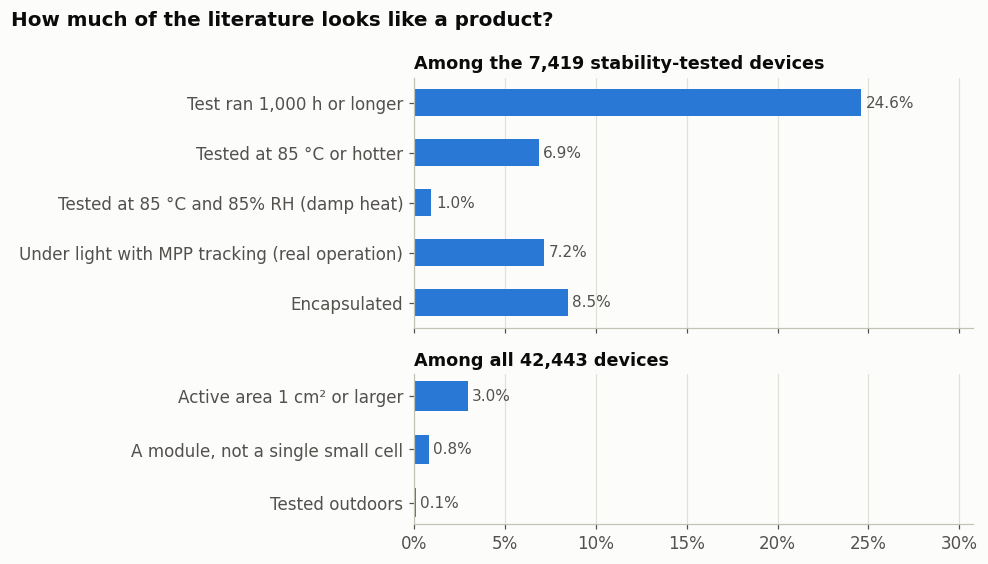

In [14]:
lens_tested = pd.Series({
    "Test ran 1,000 h or longer": tested["duration_h"].ge(1000).mean(),
    "Tested at 85 °C or hotter": tested["temp_max_c"].ge(85).mean(),
    "Tested at 85 °C and 85% RH (damp heat)": (tested["temp_max_c"].ge(85) & tested["rh_pct"].ge(85)).mean(),
    "Under light with MPP tracking (real operation)": (tested["light_condition"].eq("Illuminated")
                                                       & tested["bias"].eq("MPP tracking")).mean(),
    "Encapsulated": tested["encapsulated"].mean(),
})
lens_all = pd.Series({
    "Active area 1 cm² or larger": df["area_cm2"].ge(1).mean(),
    "A module, not a single small cell": df["module"].mean(),
    "Tested outdoors": df["outdoor"].mean(),
})

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True,
                                  gridspec_kw={"height_ratios": [len(lens_tested), len(lens_all)]})
biggest = max(lens_tested.max(), lens_all.max()) * 100
for ax, series, title in [(top, lens_tested, f"Among the {len(tested):,} stability-tested devices"),
                          (bottom, lens_all, f"Among all {len(df):,} devices")]:
    hbars(ax, series.index, series.values * 100, lambda v: f"{v:.1f}%", span=biggest)
    ax.set_title(title, fontsize=11.5)
top.set_xlim(0, biggest * 1.25)
bottom.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
fig.suptitle("How much of the literature looks like a product?", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "7_commercialization_lens")

## 8. Summary

The cell below writes out the headline numbers and saves them to `stability_gap_summary.csv`, ready to quote in a README or a post.

In [15]:
grouped = results.loc["Random forest, grouped by paper"]
randomr = results.loc["Random forest, random split"]
base = results.loc["Baseline: always guess the median"]
top_feature = imp.iloc[-1]
shelf = (tested["test_type"] == TEST_TYPES["d1"]).mean()
summary = {
    "devices": len(df), "papers": df["paper"].nunique(),
    "share_with_stability_test": len(tested) / len(df),
    "stability_share_2013": by_year["stability_share"].iloc[0],
    "stability_share_2019": by_year["stability_share"].iloc[-1],
    "t80_share_2019": by_year["t80_share"].iloc[-1],
    "devices_with_T80": int(df["t80"].notna().sum()),
    "devices_T80_plus_core_conditions": int(funnel["devices"].iloc[-1]),
    "share_of_tests_dark_shelf_life": shelf,
    "tested_outlasted_no_T80": int(outcome_counts["Outlasted the test (kept 80% or more)"]),
    "tested_fell_below_80_no_T80": int(outcome_counts["Fell below 80%, but no T80 recorded"]),
    "R2_random_split": randomr["R2"], "R2_grouped_by_paper": grouped["R2"],
    "error_factor_grouped": grouped["typical error factor"], "error_factor_baseline": base["typical error factor"],
    "top_feature": LABELS.get(top_feature["feature"], top_feature["feature"]),
    "test_conditions_share_of_importance": float(by_kind.get("How it was tested", 0) / by_kind.sum()),
    "tested_1000h_plus": lens_tested.iloc[0], "tested_damp_heat": lens_tested.iloc[2],
    "tested_light_mpp": lens_tested.iloc[3],
}
pd.Series(summary).to_csv("stability_gap_summary.csv", header=["value"])

s = summary
print(f"""
- {s['devices']:,} devices from {s['papers']:,} papers. {s['share_with_stability_test']:.1%} have any stability test,
  up from {s['stability_share_2013']:.0%} of devices in 2013 to {s['stability_share_2019']:.0%} in 2019. Lifetime (T80)
  reporting reached only {s['t80_share_2019']:.0%} by 2019.
- {s['devices_with_T80']:,} devices report a T80; {s['devices_T80_plus_core_conditions']:,} also report light, temperature,
  atmosphere and humidity.
- {s['share_of_tests_dark_shelf_life']:.0%} of stability tests are dark, room-temperature shelf-life tests.
- {s['tested_outlasted_no_T80']:,} tested devices outlasted their test, so they have no T80: the most stable
  devices are invisible to a T80 model. Another {s['tested_fell_below_80_no_T80']:,} fell below 80% with no T80 recorded.
- A random forest scores R² = {s['R2_random_split']:.2f} on a random split but {s['R2_grouped_by_paper']:.2f} when whole
  papers are held out (typical error x{s['error_factor_grouped']:.1f} vs x{s['error_factor_baseline']:.1f} for guessing the median).
- The strongest predictor of lifetime is "{s['top_feature']}"; test conditions carry
  {s['test_conditions_share_of_importance']:.0%} of the model's importance.
- {s['tested_1000h_plus']:.1%} of stability tests ran 1,000 h or more; {s['tested_damp_heat']:.1%} resemble damp heat;
  {s['tested_light_mpp']:.1%} ran under light with maximum-power-point tracking.
""")


- 42,443 devices from 7,358 papers. 17.5% have any stability test,
  up from 3% of devices in 2013 to 23% in 2019. Lifetime (T80)
  reporting reached only 6% by 2019.
- 1,832 devices report a T80; 1,306 also report light, temperature,
  atmosphere and humidity.
- 65% of stability tests are dark, room-temperature shelf-life tests.
- 3,133 tested devices outlasted their test, so they have no T80: the most stable
  devices are invisible to a T80 model. Another 2,408 fell below 80% with no T80 recorded.
- A random forest scores R² = 0.34 on a random split but 0.12 when whole
  papers are held out (typical error x4.4 vs x5.0 for guessing the median).
- The strongest predictor of lifetime is "Light vs dark"; test conditions carry
  72% of the model's importance.
- 24.6% of stability tests ran 1,000 h or more; 1.0% resemble damp heat;
  7.2% ran under light with maximum-power-point tracking.



## 9. Limitations and next steps

**Limitations**
- **Time window.** The papers here were mostly published between 2013 and 2019, before the 2020 ISOS consensus statement had time to spread, so reporting may well have improved since.
- **Extraction error.** Many values were read by hand off published figures, and the database itself flags this.
- **Selection bias.** Papers tend to report their best devices, not typical ones.
- **Defaults.** About 70% of tests list exactly 25 °C. Some of those are likely "room temperature" written as 25, which would make temperature look better reported than it really is.
- **Censoring.** The T80 model only sees devices that failed during their test. A survival model, which treats "still working when the test ended" as partial information instead of missing information, is the right next tool.

**Next steps**
- Repeat this analysis on newer literature. A 2026 preprint describes [PERLA](https://arxiv.org/abs/2601.17807), an LLM-updated version of this database in NOMAD, which would show whether reporting improved after 2020.
- Compare publication trends with patent filings ([Lens.org](https://www.lens.org/)) to see where stability work is turning into intellectual property.
- Fit a survival model (for example with the `lifelines` package) that uses the censored devices.

**Builds on:** *The challenge of studying perovskite solar cells' stability with machine learning*, Frontiers in Energy Research (2023), [doi:10.3389/fenrg.2023.1118654](https://doi.org/10.3389/fenrg.2023.1118654), which first applied random forests and learning curves to this database's stability data. ISOS test definitions: Khenkin *et al.*, *Nature Energy* **5**, 35–49 (2020), [doi:10.1038/s41560-019-0529-5](https://doi.org/10.1038/s41560-019-0529-5).